In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *

2024-08-05 21:17:36.900651: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-05 21:17:36.937102: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-05 21:17:36.937130: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-05 21:17:36.938273: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-05 21:17:36.944112: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-05 21:17:36.944772: I tensorflow/core/platform/cpu_feature_guard.cc:1

Text(0, 0.5, 'Bit value')

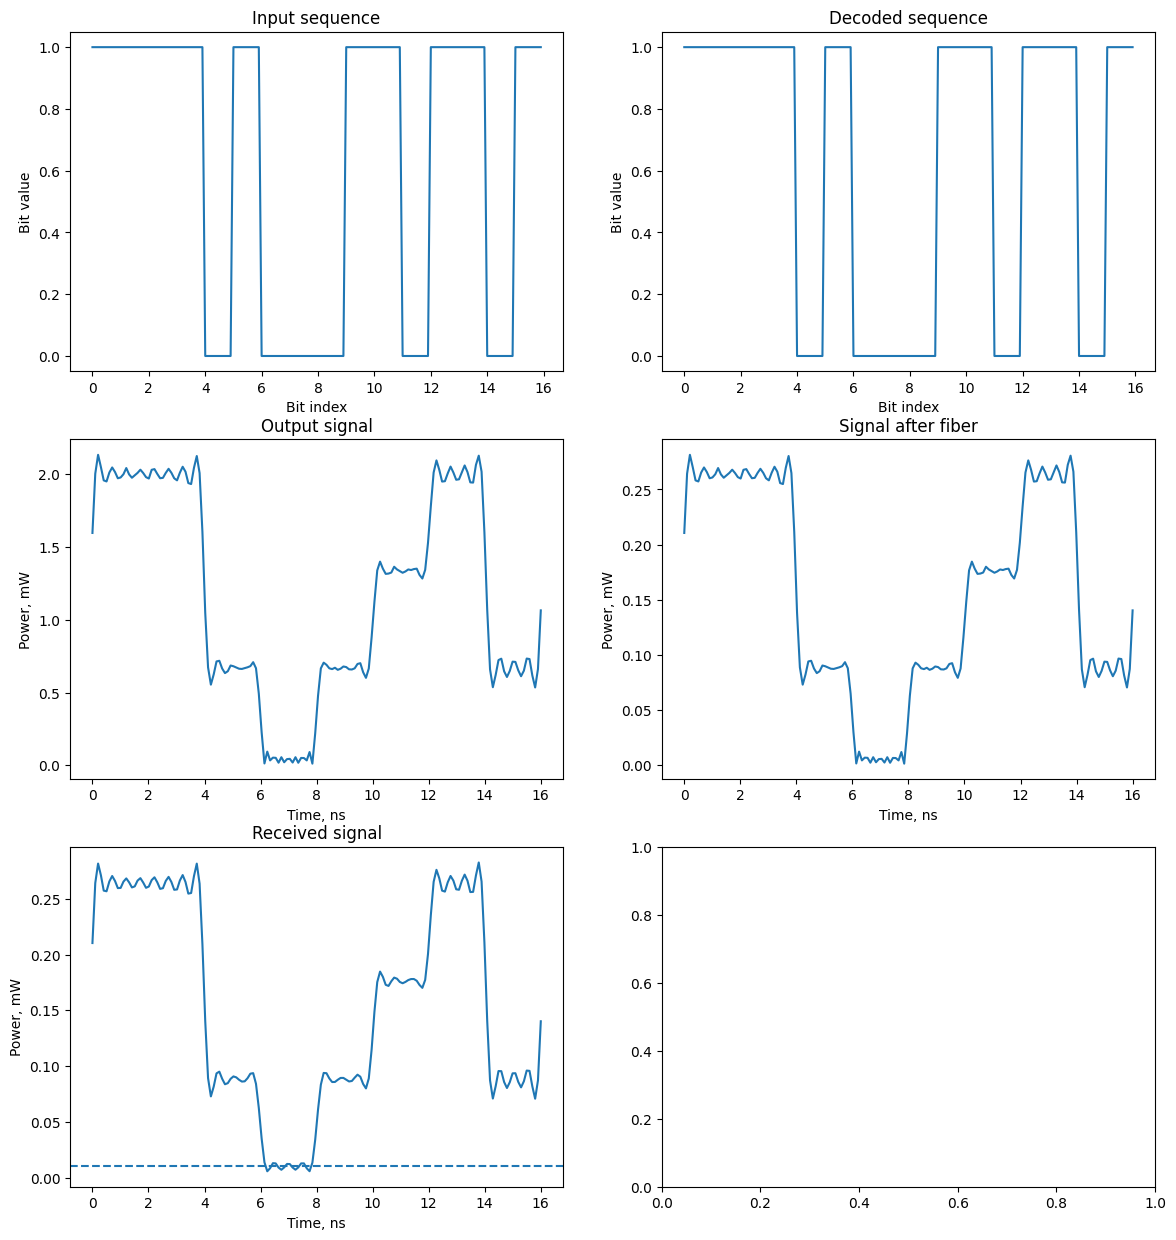

In [2]:
lpf = ElectricalLowPassFilter(cutoff_frequency=2e9)
pam_order = 2
data_rate = 1e9

transmitter = System(components=[
    PAMEncoder(sampling_rate=10e9, data_rate=data_rate, order=pam_order),
    lpf,
    IntensityModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=10e9, frequency_count=128)
    ),
    OpticalAWGN(level=-30.0)
])

channel = OpticalFiber(attenuation=0.22, length=40, chromatic_dispersion=17)
receiver = System(components=[Photodiode(), lpf])
decoder = PAMDecoder(data_rate=data_rate, order=pam_order)

system = System(components=[transmitter, channel, receiver, decoder])

input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
output_signal = transmitter(input_signal)
fiber_signal = channel(output_signal)
received_signal = receiver(fiber_signal)
decoded_signal = decoder(received_signal)

@tf.function
def estimate_ber() -> tf.Tensor:
    n_iterations = tf.constant(1000)

    ber_analyzer = BERAnalyzer()

    return tf.reduce_sum(
        tf.vectorized_map(
            fn=lambda input_seq: ber_analyzer(input_seq, system(input_seq)),
            elems=tf.vectorized_map(
                fn=lambda i: tf.random.uniform(shape=(128,), minval=0, maxval=2, dtype=tf.int32),
                elems=tf.range(n_iterations)
            )
        )
    ) / tf.cast(n_iterations, tf.float32)

fig, ((input_ax, decoded_ax), (output_ax, fiber_ax), (received_ax, _)) = plt.subplots(3, 2)
fig.set_size_inches(14, 15)

input_ax.set_title("Input sequence")
output_ax.set_title("Output signal")
fiber_ax.set_title("Signal after fiber")
received_ax.set_title("Received signal")
decoded_ax.set_title("Decoded sequence")

input_ax.plot(np.arange(0, input_signal.numpy().size, 0.1), input_signal.numpy().repeat(10))
input_ax.set_xlabel("Bit index")
input_ax.set_ylabel("Bit value")

output_ax.plot(output_signal.timing.time * 1e9, np.sum(np.abs(output_signal.samples.numpy())**2 * 1000, axis=1))
output_ax.set_xlabel("Time, ns")
output_ax.set_ylabel("Power, mW")

fiber_ax.plot(fiber_signal.timing.time * 1e9, np.sum(np.abs(fiber_signal.samples.numpy())**2 * 1000, axis=1))
fiber_ax.set_xlabel("Time, ns")
fiber_ax.set_ylabel("Power, mW")

received_ax.plot(received_signal.timing.time * 1e9, np.abs(received_signal.samples.numpy() * 1000))
received_ax.axhline(decoder.threshold * 1000, linestyle="--")
received_ax.set_xlabel("Time, ns")
received_ax.set_ylabel("Power, mW")

decoded_ax.plot(np.arange(0, decoded_signal.numpy().size, 0.1), decoded_signal.numpy().repeat(10))
decoded_ax.set_xlabel("Bit index")
decoded_ax.set_ylabel("Bit value")

In [3]:
%time estimate_ber()

2024-08-05 21:17:45.553884: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 1310720000 exceeds 10% of free system memory.
2024-08-05 21:17:45.697762: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 655360000 exceeds 10% of free system memory.
2024-08-05 21:17:45.930023: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 1310720000 exceeds 10% of free system memory.
2024-08-05 21:17:46.206907: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 655360000 exceeds 10% of free system memory.
2024-08-05 21:17:46.206937: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 655360000 exceeds 10% of free system memory.


CPU times: user 13.2 s, sys: 1.34 s, total: 14.5 s
Wall time: 6.47 s


<tf.Tensor: shape=(), dtype=float32, numpy=0.0>